# Backpropagation Derivation

## Network and Fixed Parameters

input 2개 → hidden neuron 2개 → output neuron 1개인 two-layer neural network를 다룬다. 두 layer 모두 Sigmoid activation function을 사용하며, target은 과제 예시의 $y=1$이다.

| Name | Value | Shape |
| --- | --- | --- |
| `x` | $\mathbf{x}=\begin{bmatrix}1 \\ 0\end{bmatrix}$ | $(2,1)$ |
| `W1` | $W^{(1)}=\begin{bmatrix}0.1 & 0.2 \\ 0.3 & 0.4\end{bmatrix}$ | $(2,2)$ |
| `b1` | $\mathbf{b}^{(1)}=\begin{bmatrix}0 \\ 0\end{bmatrix}$ | $(2,1)$ |
| `W2` | $W^{(2)}=\begin{bmatrix}0.5 & 0.6\end{bmatrix}$ | $(1,2)$ |
| `b2` | $b_1^{(2)}=0$ | scalar |
| `y_true` | $y=1$ | scalar |

$w_{ij}^{(l)}$은 이전 layer의 $j$번째 neuron에서 현재 layer의 $i$번째 neuron으로 연결되는 weight이다. $z$는 weighted sum, $a$는 activation output을 뜻한다.

$$
\sigma(t)=\frac{1}{1+e^{-t}}.
$$

중간 계산에는 반올림 전 값을 사용하고, NumPy 검증에서 소수점 4자리로 비교한다.

## Forward Propagation by Hand

### Input → Hidden Layer: `z1`, `a1`

$$
\mathbf{z}^{(1)}=W^{(1)}\mathbf{x}+\mathbf{b}^{(1)}
=\begin{bmatrix}
0.1\times1+0.2\times0+0 \\
0.3\times1+0.4\times0+0
\end{bmatrix}
=\begin{bmatrix}0.1 \\ 0.3\end{bmatrix},
\qquad \text{shape: }(2,1).
$$

Sigmoid를 element-wise로 적용한다.

$$
\mathbf{a}^{(1)}=\sigma\!\left(\mathbf{z}^{(1)}\right)
=\begin{bmatrix}
(1+e^{-0.1})^{-1} \\
(1+e^{-0.3})^{-1}
\end{bmatrix}
\approx\begin{bmatrix}0.5249791875 \\ 0.5744425168\end{bmatrix},
\qquad \text{shape: }(2,1).
$$

### Hidden Layer → Output Layer: `z2`, `y_pred`, `loss`

$$
\begin{aligned}
z_1^{(2)}
&=w_{11}^{(2)}a_1^{(1)}+w_{12}^{(2)}a_2^{(1)}+b_1^{(2)} \\
&=0.5\sigma(0.1)+0.6\sigma(0.3)+0
\approx0.6071551038, \\
\hat{y}
&=\sigma\!\left(z_1^{(2)}\right)
=\frac{1}{1+e^{-z_1^{(2)}}}
\approx0.6472915700.
\end{aligned}
$$

`z2`와 `y_pred`는 scalar이다. NumPy에서는 $(1,2)\ @\ (2,1)$ matrix multiplication 결과의 유일한 element를 꺼내 `z2`로 사용한다.

Binary Cross-Entropy(BCE) loss도 scalar이며, $y=1$을 대입하면 다음과 같다.

$$
\begin{aligned}
L&=-\left[y\log\hat{y}+(1-y)\log(1-\hat{y})\right] \\
&=-\log\hat{y}\approx0.4349584369.
\end{aligned}
$$

## Backpropagation Using the Chain Rule

loss에서 output layer, hidden layer 순서로 chain rule을 적용한다. $\odot$는 element-wise product이며, 각 gradient는 해당 variable과 같은 shape이다.

### Step 1. $\partial L/\partial\hat{y}$

$$
\begin{aligned}
\frac{\partial L}{\partial\hat{y}}
&=-\frac{y}{\hat{y}}+\frac{1-y}{1-\hat{y}} \\
&=\frac{\hat{y}-y}{\hat{y}(1-\hat{y})}.
\end{aligned}
$$

$y=1$을 대입하면 $\partial L/\partial\hat{y}=-1/\hat{y}\approx-1.5448988468$이며, scalar이다.

### Step 2. $\partial L/\partial z_1^{(2)}$ (Output Layer Checkpoint)

Sigmoid의 derivative는 $\sigma'(t)=e^{-t}/(1+e^{-t})^2=\sigma(t)(1-\sigma(t))$이다.

$$
\begin{aligned}
\delta_1^{(2)}:=\frac{\partial L}{\partial z_1^{(2)}}
&=\frac{\partial L}{\partial\hat{y}}
\frac{\partial\hat{y}}{\partial z_1^{(2)}} \\
&=\frac{\hat{y}-y}{\hat{y}(1-\hat{y})}\,\hat{y}(1-\hat{y}) \\
&=\boxed{\hat{y}-y}.
\end{aligned}
$$

$\delta_1^{(2)}=0.6472915700-1\approx-0.3527084300$이며, scalar이다.

### Step 3. $\partial L/\partial W^{(2)}$

output layer의 weighted sum에서 $\partial z_1^{(2)}/\partial w_{1i}^{(2)}=a_i^{(1)}$이므로,

$$
\frac{\partial L}{\partial w_{1i}^{(2)}}
=\frac{\partial L}{\partial z_1^{(2)}}
\frac{\partial z_1^{(2)}}{\partial w_{1i}^{(2)}}
=\delta_1^{(2)}a_i^{(1)},\qquad i=1,2.
$$

$$
\frac{\partial L}{\partial W^{(2)}}
=\delta_1^{(2)}\left(\mathbf{a}^{(1)}\right)^{\mathsf T}
\approx\begin{bmatrix}-0.1851645850 & -0.2026107182\end{bmatrix},
\qquad \text{shape: }(1,2).
$$

bias는 $\partial z_1^{(2)}/\partial b_1^{(2)}=1$이므로 $\partial L/\partial b_1^{(2)}=\delta_1^{(2)}\approx-0.3527084300$ (scalar)이다.

### Step 4. $\partial L/\partial\mathbf{a}^{(1)}$

output layer의 weighted sum에서 $\partial z_1^{(2)}/\partial a_i^{(1)}=w_{1i}^{(2)}$이므로,

$$
\frac{\partial L}{\partial a_i^{(1)}}
=\frac{\partial L}{\partial z_1^{(2)}}
\frac{\partial z_1^{(2)}}{\partial a_i^{(1)}}
=\delta_1^{(2)}w_{1i}^{(2)}.
$$

$$
\frac{\partial L}{\partial\mathbf{a}^{(1)}}
=\left(W^{(2)}\right)^{\mathsf T}\delta_1^{(2)}
\approx\begin{bmatrix}
0.5\times(-0.3527084300) \\
0.6\times(-0.3527084300)
\end{bmatrix}
\approx\begin{bmatrix}-0.1763542150 \\ -0.2116250580\end{bmatrix},
\qquad \text{shape: }(2,1).
$$

### Step 5. $\partial L/\partial\mathbf{z}^{(1)}$ (Hidden Layer Checkpoint)

각 hidden neuron에 자신의 Sigmoid derivative를 곱한다.

$$
\delta_i^{(1)}:=\frac{\partial L}{\partial z_i^{(1)}}
=\frac{\partial L}{\partial a_i^{(1)}}
\frac{\partial a_i^{(1)}}{\partial z_i^{(1)}}
=\frac{\partial L}{\partial a_i^{(1)}}a_i^{(1)}(1-a_i^{(1)}).
$$

$$
\begin{aligned}
\boldsymbol{\delta}^{(1)}
&=\frac{\partial L}{\partial\mathbf{a}^{(1)}}
\odot\mathbf{a}^{(1)}\odot\left(1-\mathbf{a}^{(1)}\right) \\
&\approx\begin{bmatrix}
-0.1763542150\times0.5249791875\times(1-0.5249791875) \\
-0.2116250580\times0.5744425168\times(1-0.5744425168)
\end{bmatrix} \\
&\approx\begin{bmatrix}-0.0439785158 \\ -0.0517335044\end{bmatrix},
\qquad \text{shape: }(2,1).
\end{aligned}
$$

### Step 6. $\partial L/\partial W^{(1)}$

$z_i^{(1)}=\sum_jw_{ij}^{(1)}x_j+b_i^{(1)}$에서 $\partial z_i^{(1)}/\partial w_{ij}^{(1)}=x_j$이므로,

$$
\frac{\partial L}{\partial w_{ij}^{(1)}}
=\frac{\partial L}{\partial z_i^{(1)}}
\frac{\partial z_i^{(1)}}{\partial w_{ij}^{(1)}}
=\delta_i^{(1)}x_j,\qquad i,j\in\{1,2\}.
$$

이를 outer product로 묶으면 네 weight의 gradient를 얻는다.

$$
\frac{\partial L}{\partial W^{(1)}}
=\boldsymbol{\delta}^{(1)}\mathbf{x}^{\mathsf T}
\approx\begin{bmatrix}
-0.0439785158 \\
-0.0517335044
\end{bmatrix}\begin{bmatrix}1 & 0\end{bmatrix}
=\begin{bmatrix}
-0.0439785158 & 0 \\
-0.0517335044 & 0
\end{bmatrix},
\qquad \text{shape: }(2,2).
$$

두 번째 column은 $x_2=0$이므로 모두 0이다. bias는 $\partial z_i^{(1)}/\partial b_i^{(1)}=1$이므로,

$$
\frac{\partial L}{\partial\mathbf{b}^{(1)}}
=\boldsymbol{\delta}^{(1)}
\approx\begin{bmatrix}-0.0439785158 \\ -0.0517335044\end{bmatrix},
\qquad \text{shape: }(2,1).
$$

## Computational Graph

앞의 hand calculation을 같은 computational graph에서 따라가 보자. 각 box는 variable과 그 값을 만드는 operation을 나타내고, arrow는 data dependency를 나타낸다. hidden neuron 2개를 각각 펼쳐서 weighted sum과 Sigmoid를 구분했다.

- **Forward propagation (blue)**: $\mathbf{x}$에서 $L$까지 값을 전달한다. weighted sum box 안에는 기존 예시의 weight와 bias를 표시했다.
- **Backpropagation (red)**: $\partial L/\partial L=1$에서 시작해 반대 방향으로 이동하며, 전달받은 gradient에 arrow의 **local derivative**를 곱한다.

그림의 숫자는 앞의 hand calculation을 소수점 4자리로 표시한 label이다. 아래 NumPy 검증에서는 반올림 전 값으로 계산한다.

In [1]:
# Import the plotting tools used to draw the computational graphs.

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

In [2]:
# Define shared drawing helpers so both graphs use the same layout.

# Create a canvas with aligned columns for the forward and backward variables.
def make_graph_axes(title, first_heading):
    figure, axis = plt.subplots(figsize=(18, 6.3), dpi=110)
    figure.set_facecolor("white")
    axis.set(xlim=(-0.2, 20), ylim=(-0.1, 7.3))
    axis.axis("off")
    axis.set_title(title, loc="left", fontsize=17, fontweight="bold", pad=15)
    headings = [
        (1.4, first_heading), (4.6, "Hidden: weighted sum"),
        (8.0, "Hidden: Sigmoid"), (11.5, "Output: weighted sum"),
        (15.1, "Output: Sigmoid"), (18.6, "BCE loss"),
    ]
    for position, heading in headings:
        axis.text(position, 6.95, heading, ha="center", color="#475569", fontsize=10)
    return figure, axis


# Draw a variable box and return its geometry for connecting arrows.
def draw_graph_node(axis, center, label, width=2.4, height=1.5, backward=False):
    x_center, y_center = center
    edge, face = ("#b42318", "#fff1ed") if backward else ("#1d4ed8", "#eff6ff")
    box = FancyBboxPatch(
        (x_center - width / 2, y_center - height / 2), width, height,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        facecolor=face, edgecolor=edge, linewidth=1.4, zorder=2,
    )
    axis.add_patch(box)
    axis.text(
        x_center, y_center, label, ha="center", va="center", fontsize=11,
        linespacing=1.7, color="#172033", zorder=3,
    )
    return x_center, y_center, width, height


# Clip arrows to the box boundaries and optionally label a local derivative.
def draw_graph_arrow(axis, source, target, label="", offset=(0, 0.5), backward=False):
    source_x, source_y, source_width, source_height = source
    target_x, target_y, target_width, target_height = target
    dx, dy = target_x - source_x, target_y - source_y
    # Intersect the center-to-center line with each rectangular boundary.
    source_scale = min(
        source_width / (2 * abs(dx)) if dx else float("inf"),
        source_height / (2 * abs(dy)) if dy else float("inf"),
    )
    target_scale = min(
        target_width / (2 * abs(dx)) if dx else float("inf"),
        target_height / (2 * abs(dy)) if dy else float("inf"),
    )
    start = (source_x + source_scale * dx, source_y + source_scale * dy)
    end = (target_x - target_scale * dx, target_y - target_scale * dy)
    color = "#b42318" if backward else "#1d4ed8"
    axis.add_patch(FancyArrowPatch(
        start, end, arrowstyle="-|>", mutation_scale=16,
        linewidth=1.7, color=color, shrinkA=5, shrinkB=5, zorder=1,
    ))
    if label:
        axis.text(
            (start[0] + end[0]) / 2 + offset[0],
            (start[1] + end[1]) / 2 + offset[1], label,
            ha="center", va="center", fontsize=10, color=color,
            bbox={"facecolor": "white", "edgecolor": "none", "pad": 1.5},
            zorder=4,
        )

### Forward Propagation: $\mathbf{x}\rightarrow L$

위쪽 경로는 첫 번째 hidden neuron, 아래쪽 경로는 두 번째 hidden neuron이다. 두 activation이 output의 weighted sum에서 합쳐진 뒤, Sigmoid와 BCE loss를 거친다. 이 예시는 $y=1$이므로 BCE loss가 $-\log\hat{y}$로 단순해진다.

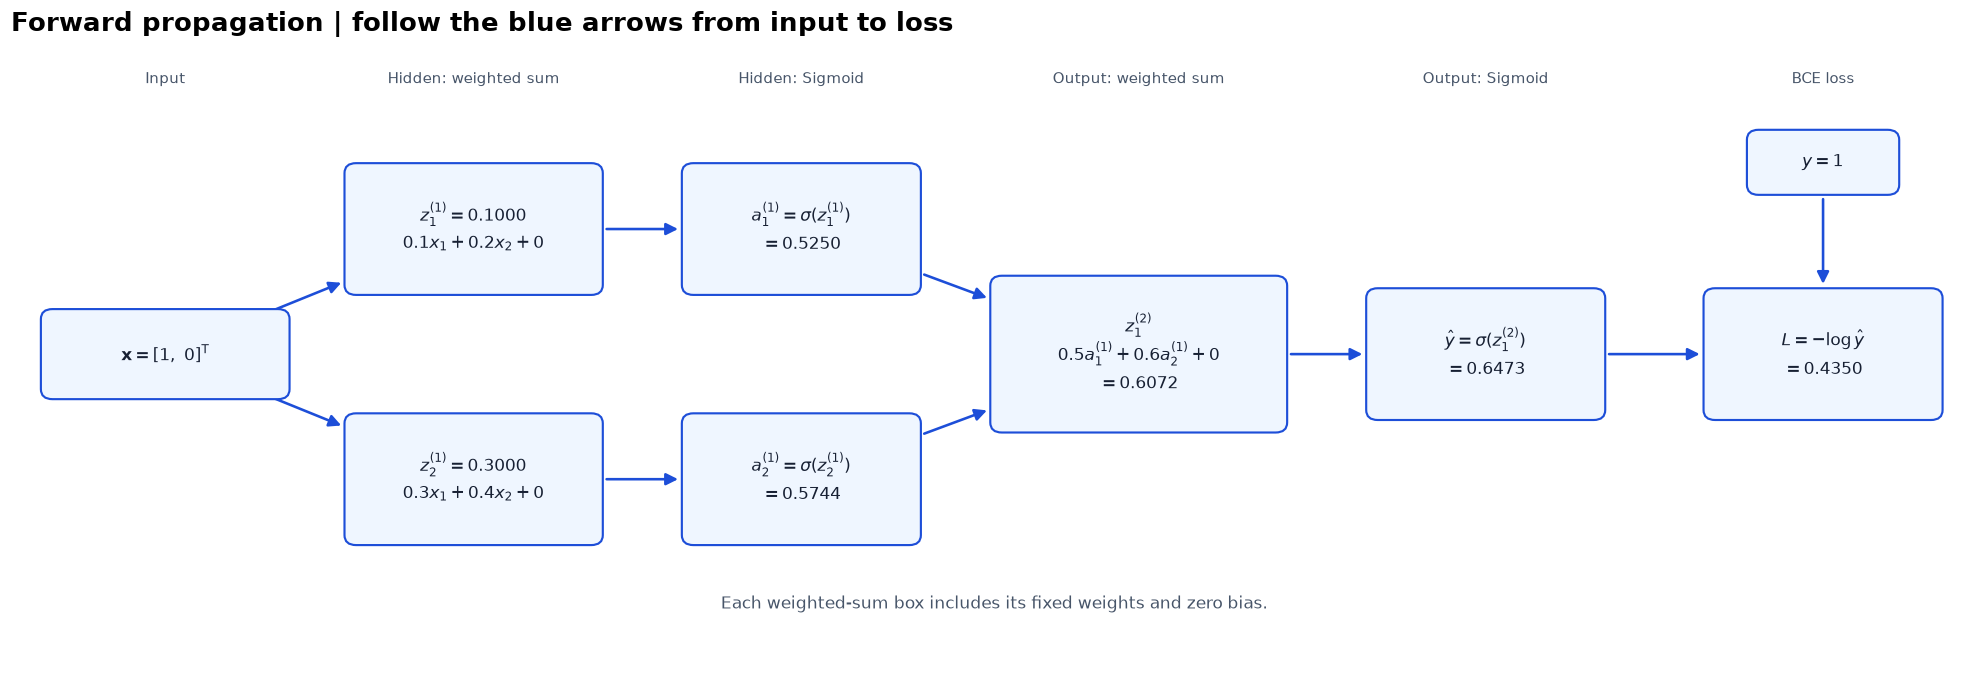

In [3]:
# Visualize the existing example as operations with their forward values.

forward_figure, forward_axis = make_graph_axes(
    "Forward propagation | follow the blue arrows from input to loss", "Input"
)
forward_nodes = {
    "x": draw_graph_node(forward_axis, (1.4, 3.7),
        r"$\mathbf{x}=[1,\ 0]^{\mathsf{T}}$", width=2.5, height=1.0),
    "z11": draw_graph_node(forward_axis, (4.6, 5.2),
        r"$z_1^{(1)}=0.1000$" "\n" r"$0.1x_1+0.2x_2+0$", width=2.6),
    "z12": draw_graph_node(forward_axis, (4.6, 2.2),
        r"$z_2^{(1)}=0.3000$" "\n" r"$0.3x_1+0.4x_2+0$", width=2.6),
    "a11": draw_graph_node(forward_axis, (8.0, 5.2),
        r"$a_1^{(1)}=\sigma(z_1^{(1)})$" "\n" r"$=0.5250$"),
    "a12": draw_graph_node(forward_axis, (8.0, 2.2),
        r"$a_2^{(1)}=\sigma(z_2^{(1)})$" "\n" r"$=0.5744$"),
    "z2": draw_graph_node(forward_axis, (11.5, 3.7),
        r"$z_1^{(2)}$" "\n" r"$0.5a_1^{(1)}+0.6a_2^{(1)}+0$" "\n" r"$=0.6072$",
        width=3.0, height=1.8),
    "y_pred": draw_graph_node(forward_axis, (15.1, 3.7),
        r"$\hat{y}=\sigma(z_1^{(2)})$" "\n" r"$=0.6473$"),
    "loss": draw_graph_node(forward_axis, (18.6, 3.7),
        r"$L=-\log\hat{y}$" "\n" r"$=0.4350$"),
    "target": draw_graph_node(forward_axis, (18.6, 6.0),
        r"$y=1$", width=1.5, height=0.7),
}
for source, target in [
    ("x", "z11"), ("x", "z12"), ("z11", "a11"), ("z12", "a12"),
    ("a11", "z2"), ("a12", "z2"), ("z2", "y_pred"),
    ("y_pred", "loss"), ("target", "loss"),
]:
    draw_graph_arrow(forward_axis, forward_nodes[source], forward_nodes[target])
forward_axis.text(
    10, 0.65, "Each weighted-sum box includes its fixed weights and zero bias.",
    ha="center", fontsize=11, color="#475569",
)
forward_figure.tight_layout()
plt.show()

### Backpropagation: $L\rightarrow$ Parameter Gradients

같은 배치에서 arrow를 뒤집어 읽는다. **각 box의 값은 $\partial L/\partial(\text{해당 variable})$**이고, arrow의 $\times$ 뒤에는 local derivative가 있다. $\delta_i^{(l)}=\partial L/\partial z_i^{(l)}$ 표기도 앞의 derivation과 같다.

예를 들어 output의 gradient $-0.3527$은 두 hidden neuron에 각각 weight $0.5$, $0.6$을 곱해서 전달된다. 위쪽 경로에서는 $-0.1764$에 Sigmoid derivative $0.2494$를 곱해 $\delta_1^{(1)}\approx-0.0440$을 얻는다. 그림에서는 반올림한 값을 보여주지만, chain rule 자체는 반올림 전 값에 적용한다.

왼쪽 box의 $\mathbf{w}_{i:}^{(1)}$는 $W^{(1)}$의 $i$번째 row이다. weighted sum에서는 전달받은 $\delta$에 **input을 곱하면 weight gradient**, **1을 곱하면 bias gradient**가 된다.

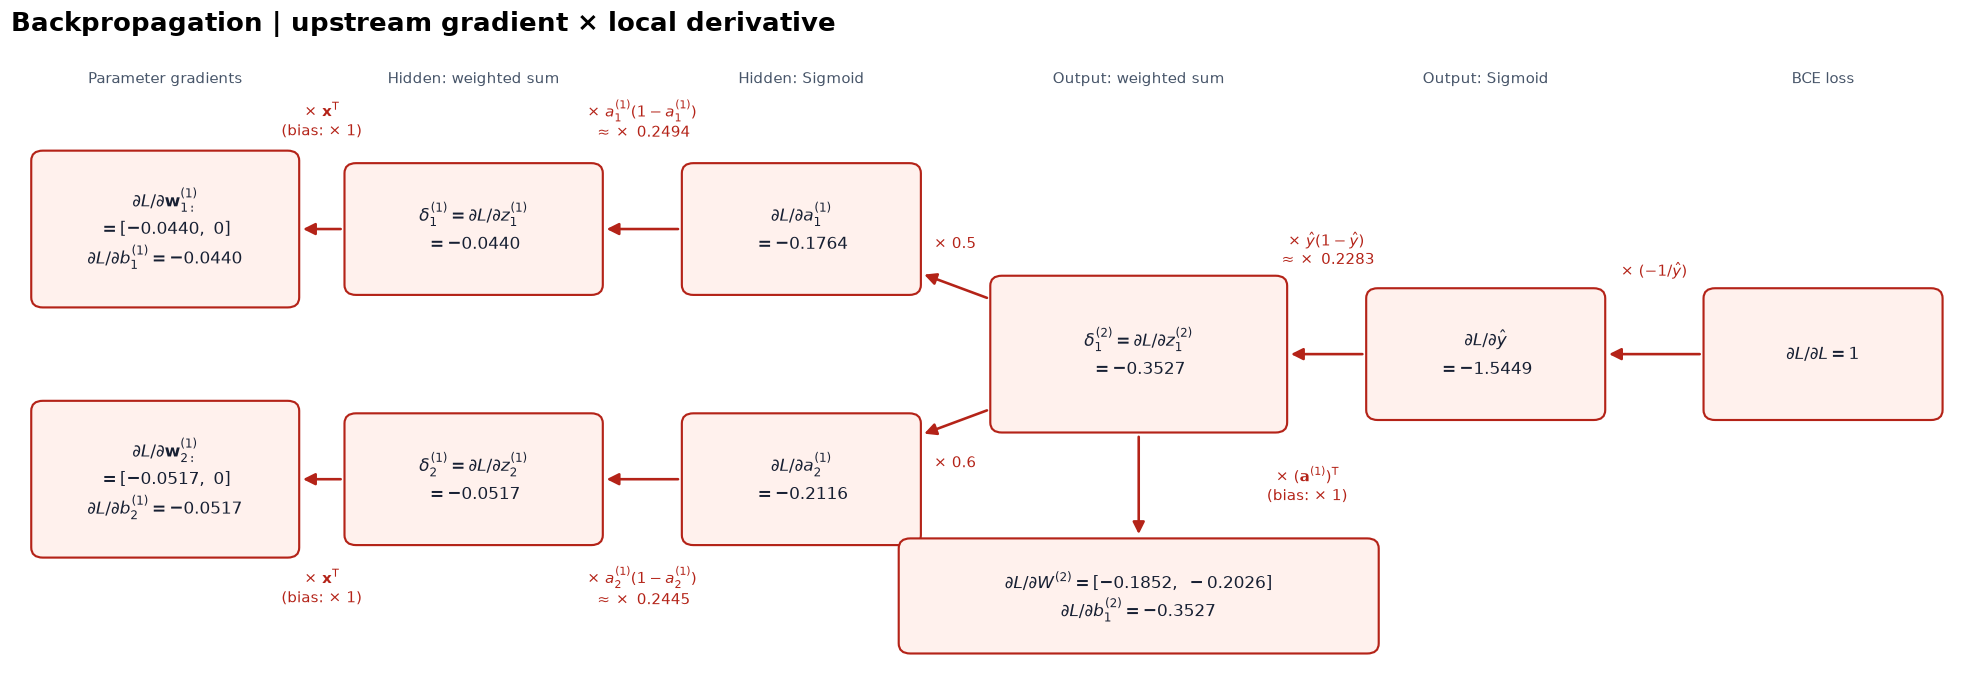

In [4]:
# Trace upstream gradients through local derivatives to all weights and biases.

backward_figure, backward_axis = make_graph_axes(
    "Backpropagation | upstream gradient × local derivative", "Parameter gradients"
)
backward_labels = {
    "W11": ((1.4, 5.2),
        r"$\partial L/\partial\mathbf{w}_{1:}^{(1)}$" "\n" r"$=[-0.0440,\ 0]$" "\n"
        r"$\partial L/\partial b_1^{(1)}=-0.0440$", 2.7, 1.8),
    "W12": ((1.4, 2.2),
        r"$\partial L/\partial\mathbf{w}_{2:}^{(1)}$" "\n" r"$=[-0.0517,\ 0]$" "\n"
        r"$\partial L/\partial b_2^{(1)}=-0.0517$", 2.7, 1.8),
    "z11": ((4.6, 5.2),
        r"$\delta_1^{(1)}=\partial L/\partial z_1^{(1)}$" "\n" r"$=-0.0440$", 2.6, 1.5),
    "z12": ((4.6, 2.2),
        r"$\delta_2^{(1)}=\partial L/\partial z_2^{(1)}$" "\n" r"$=-0.0517$", 2.6, 1.5),
    "a11": ((8.0, 5.2),
        r"$\partial L/\partial a_1^{(1)}$" "\n" r"$=-0.1764$", 2.4, 1.5),
    "a12": ((8.0, 2.2),
        r"$\partial L/\partial a_2^{(1)}$" "\n" r"$=-0.2116$", 2.4, 1.5),
    "z2": ((11.5, 3.7),
        r"$\delta_1^{(2)}=\partial L/\partial z_1^{(2)}$" "\n" r"$=-0.3527$", 3.0, 1.8),
    "y_pred": ((15.1, 3.7),
        r"$\partial L/\partial\hat{y}$" "\n" r"$=-1.5449$", 2.4, 1.5),
    "loss": ((18.6, 3.7), r"$\partial L/\partial L=1$", 2.4, 1.5),
    "W2": ((11.5, 0.8),
        r"$\partial L/\partial W^{(2)}=[-0.1852,\ -0.2026]$" "\n"
        r"$\partial L/\partial b_1^{(2)}=-0.3527$", 4.9, 1.3),
}
backward_nodes = {
    name: draw_graph_node(backward_axis, center, label, width, height, backward=True)
    for name, (center, label, width, height) in backward_labels.items()
}
for source, target, label, offset in [
    ("loss", "y_pred", r"$\times\ (-1/\hat{y})$", (0, 1.0)),
    ("y_pred", "z2", r"$\times\ \hat{y}(1-\hat{y})$" "\n" r"$\approx\times\ 0.2283$", (0, 1.25)),
    ("z2", "a11", r"$\times\ 0.5$", (0, 0.5)),
    ("z2", "a12", r"$\times\ 0.6$", (0, -0.5)),
    ("a11", "z11", r"$\times\ a_1^{(1)}(1-a_1^{(1)})$" "\n" r"$\approx\times\ 0.2494$", (0, 1.3)),
    ("a12", "z12", r"$\times\ a_2^{(1)}(1-a_2^{(1)})$" "\n" r"$\approx\times\ 0.2445$", (0, -1.3)),
    ("z11", "W11", r"$\times\ \mathbf{x}^{\mathsf{T}}$" "\n" r"(bias: $\times\ 1$)", (0, 1.3)),
    ("z12", "W12", r"$\times\ \mathbf{x}^{\mathsf{T}}$" "\n" r"(bias: $\times\ 1$)", (0, -1.3)),
    ("z2", "W2", r"$\times\ (\mathbf{a}^{(1)})^{\mathsf{T}}$" "\n" r"(bias: $\times\ 1$)", (1.75, 0)),
]:
    draw_graph_arrow(
        backward_axis, backward_nodes[source], backward_nodes[target],
        label, offset, backward=True,
    )
backward_figure.tight_layout()
plt.show()

그림에서 확인할 점:

- **BCE + Sigmoid**: $(-1/\hat{y})\,\hat{y}(1-\hat{y})=\hat{y}-1$이므로 output의 $\delta_1^{(2)}\approx-0.3527$이다.
- **Branch**: output에서 두 hidden neuron으로 돌아갈 때는 각 연결의 weight를 곱한다. forward에서 두 값이 합쳐졌다고 해서 backward gradient를 절반씩 나누지 않는다.
- **Zero input**: $x_2=0$이므로 $\partial L/\partial w_{12}^{(1)}=\delta_1^{(1)}x_2=0$, $\partial L/\partial w_{22}^{(1)}=\delta_2^{(1)}x_2=0$이다. hidden neuron의 $\delta$와 bias gradient는 0이 아니다.

이 흐름을 아래에서 NumPy의 matrix operation으로 검증한다.

## NumPy Verification

같은 input으로 forward propagation과 backpropagation을 수행한 뒤, 위 손계산을 소수점 4자리로 반올림한 값 및 shape과 비교한다.

In [5]:
# Import NumPy for the forward and backward calculations.

import numpy as np

In [6]:
# Define the activation function used by both layers.

# Apply Sigmoid element-wise to a scalar or array.
def sigmoid(value):
    """Return the element-wise Sigmoid activation."""
    return 1.0 / (1.0 + np.exp(-value))

In [7]:
# Set the fixed input, parameters, and target from the hand calculation.

x = np.array([[1.0], [0.0]])
W1 = np.array([[0.1, 0.2], [0.3, 0.4]])
b1 = np.zeros((2, 1))
W2 = np.array([[0.5, 0.6]])
b2 = 0.0
y_true = 1.0

In [8]:
# Compute the forward intermediates and BCE loss without rounding.

z1 = W1 @ x + b1
a1 = sigmoid(z1)
# Extract the sole element of the (1, 1) matrix product as a scalar.
z2 = (W2 @ a1).item() + b2
y_pred = sigmoid(z2)
loss = -(y_true * np.log(y_pred) + (1.0 - y_true) * np.log(1.0 - y_pred))

In [9]:
# Apply the chain rule through the output layer.

d_y_pred = -y_true / y_pred + (1.0 - y_true) / (1.0 - y_pred)
d_z2 = d_y_pred * y_pred * (1.0 - y_pred)
d_W2 = d_z2 * a1.T
d_b2 = d_z2
# Transpose the output weights to send the scalar gradient to both hidden neurons.
d_a1 = W2.T * d_z2

In [10]:
# Propagate the gradient through the hidden activation to its weights and bias.

d_z1 = d_a1 * a1 * (1.0 - a1)
# The outer product restores the weight shape: (2, 1) @ (1, 2) -> (2, 2).
d_W1 = d_z1 @ x.T
d_b1 = d_z1.copy()

In [11]:
# Record the four-decimal hand-calculation references and their shapes.

hand_results = {
    "z1": np.array([[0.1000], [0.3000]]),
    "a1": np.array([[0.5250], [0.5744]]),
    "z2": 0.6072,
    "y_pred": 0.6473,
    "loss": 0.4350,
    "d_y_pred": -1.5449,
    "d_z2": -0.3527,
    "d_W2": np.array([[-0.1852, -0.2026]]),
    "d_b2": -0.3527,
    "d_a1": np.array([[-0.1764], [-0.2116]]),
    "d_z1": np.array([[-0.0440], [-0.0517]]),
    "d_W1": np.array([[-0.0440, 0.0000], [-0.0517, 0.0000]]),
    "d_b1": np.array([[-0.0440], [-0.0517]]),
}

In [12]:
# Compare all values and shapes with the hand calculations to four decimal places.

np.testing.assert_allclose(d_z2, y_pred - y_true, rtol=1e-12, atol=1e-14)
numpy_results = {
    "z1": z1, "a1": a1, "z2": z2, "y_pred": y_pred, "loss": loss,
    "d_y_pred": d_y_pred, "d_z2": d_z2, "d_W2": d_W2, "d_b2": d_b2,
    "d_a1": d_a1, "d_z1": d_z1, "d_W1": d_W1, "d_b1": d_b1,
}
for name, expected in hand_results.items():
    actual = np.round(numpy_results[name], decimals=4)
    np.testing.assert_array_equal(actual, expected, strict=True, err_msg=name)
    shape = np.shape(actual) or "scalar"
    # Add zero only for display to avoid printing negative zero.
    value = np.array2string(
        np.asarray(actual) + 0.0, precision=4, floatmode="fixed", separator=", "
    ).replace("\n", " ")
    print(f"{name} | shape={shape} | hand = NumPy = {value} | PASS")

print("All values and shapes match the hand calculations to 4 decimal places.")

z1 | shape=(2, 1) | hand = NumPy = [[0.1000],  [0.3000]] | PASS
a1 | shape=(2, 1) | hand = NumPy = [[0.5250],  [0.5744]] | PASS
z2 | shape=scalar | hand = NumPy = 0.6072 | PASS
y_pred | shape=scalar | hand = NumPy = 0.6473 | PASS
loss | shape=scalar | hand = NumPy = 0.4350 | PASS
d_y_pred | shape=scalar | hand = NumPy = -1.5449 | PASS
d_z2 | shape=scalar | hand = NumPy = -0.3527 | PASS
d_W2 | shape=(1, 2) | hand = NumPy = [[-0.1852, -0.2026]] | PASS
d_b2 | shape=scalar | hand = NumPy = -0.3527 | PASS
d_a1 | shape=(2, 1) | hand = NumPy = [[-0.1764],  [-0.2116]] | PASS
d_z1 | shape=(2, 1) | hand = NumPy = [[-0.0440],  [-0.0517]] | PASS
d_W1 | shape=(2, 2) | hand = NumPy = [[-0.0440,  0.0000],  [-0.0517,  0.0000]] | PASS
d_b1 | shape=(2, 1) | hand = NumPy = [[-0.0440],  [-0.0517]] | PASS
All values and shapes match the hand calculations to 4 decimal places.
